## Importar las librerias de DL

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

## Cargamos el conjunto de datos

In [31]:
fashion_mnist = keras.datasets.fashion_mnist
(X_train, y_train),(X_test, y_test) = fashion_mnist.load_data()

print("El conjunto X_train tiene: ", X_train.shape)
print("El conjunto y_train tiene: ", y_train.shape)
print("El conjunto X_test tiene: ", X_test.shape)
print("El conjunto y_test tiene: ", y_test.shape)

El conjunto X_train tiene:  (60000, 28, 28)
El conjunto y_train tiene:  (60000,)
El conjunto X_test tiene:  (10000, 28, 28)
El conjunto y_test tiene:  (10000,)


## Visulizar los datos

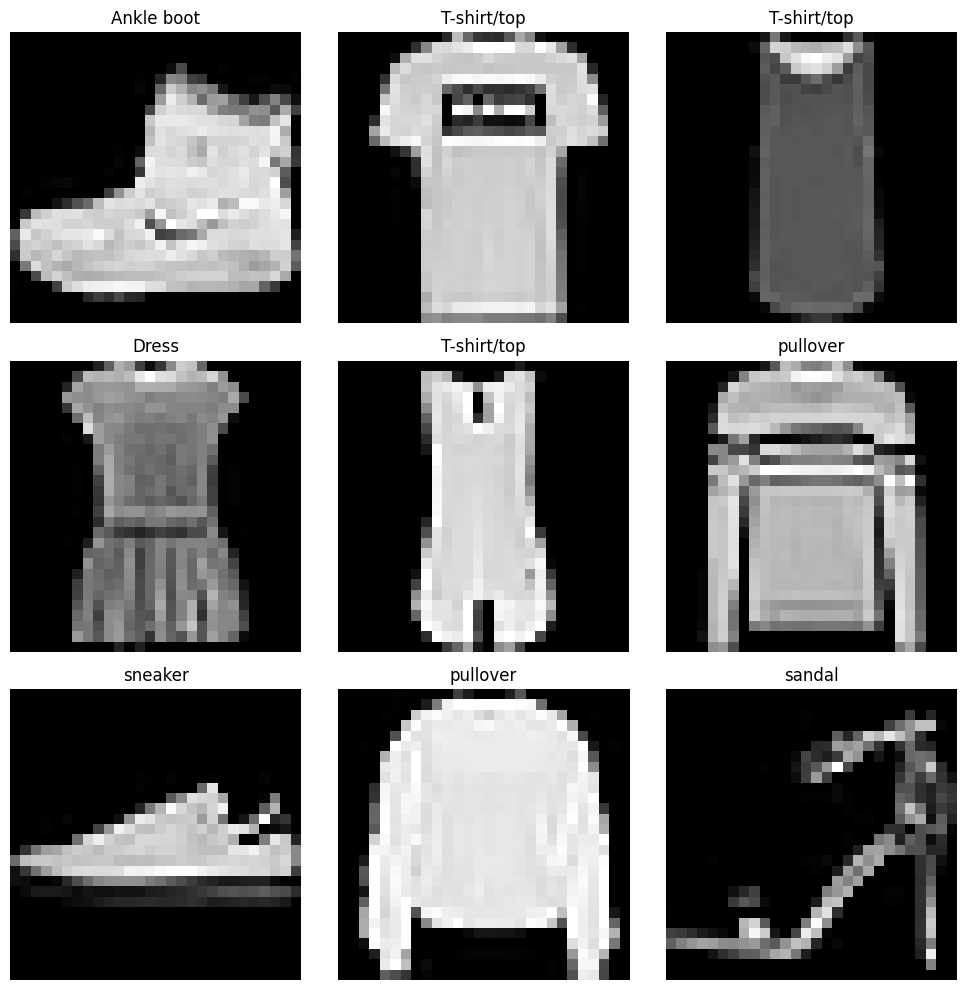

In [32]:
class_names = ['T-shirt/top', 'Trouser', 'pullover', 'Dress', 'Coat', 
                'sandal', 'Shirt', 'sneaker', 'Bag', 'Ankle boot'
                ]
plt.figure(figsize=(10,10))
for i in range (9):
    plt.subplot(3, 3, i+1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(class_names[y_train[i]])
    plt.axis('off')
plt.tight_layout()
plt.show()

## Pre procesamiento de los datos

In [33]:
X_train = X_train/255.0
X_test = X_test/255.0  # se normalizan las imágenes, NO las etiquetas

## visualicemos las imagenes binarizadas

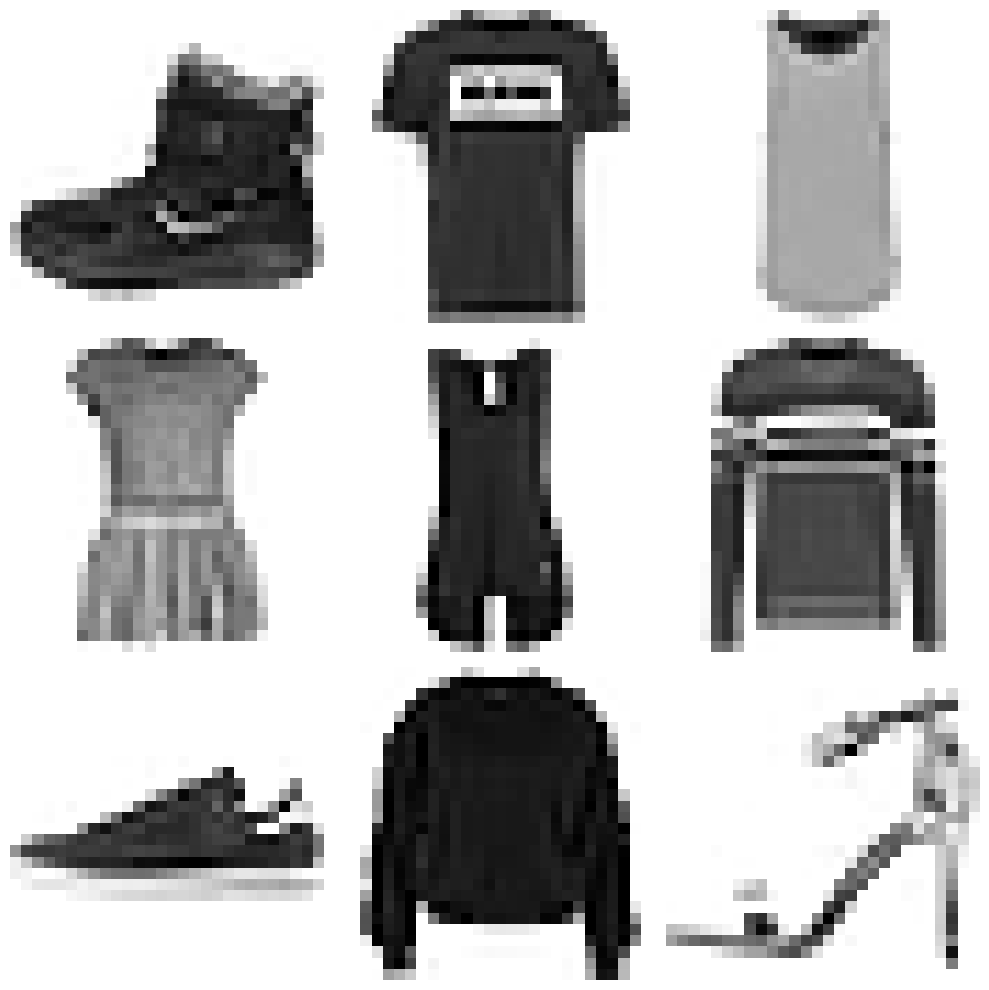

In [34]:
plt.figure(figsize=(10,10))

for i in range(9):
    plt.subplot(3,3,i+1)
    plt.imshow(X_train[i], cmap='binary')
    plt.axis('off')
plt.tight_layout()
plt.show()

## Construimos nuestro modelo de IA (ANN)

In [35]:
model = keras.Sequential([
    layers.Flatten(input_shape=(28,28)), #Convierte la imagen en un vector de 784 posiciones
    # capas ocultas
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax') # 10 neuronas de salida (softmax para multiclase)
])

/Users/macbook/Library/Python/3.9/lib/python/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


## Compilamos el modelo

In [36]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

## Resumen del modelo

In [37]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

## Entrenamos el modelo de IA

In [39]:
history = model.fit(
    X_train, y_train,
    epochs=10,
    validation_split=0.20
)

Epoch 1/10


AttributeError: 'Adam' object has no attribute '_momentums'

## Evaluemos el modelo

In [10]:
test_loss, test_acc = model.evaluate(X_test, y_test)
print(test_acc)
print(test_loss)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 373us/step - accuracy: 0.1001 - loss: 32862.1328
0.10000000149011612
32739.412109375


## Predicciones

In [11]:
predicciones = model.predict(X_test)
y_pred = np.argmax(predicciones, axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 322us/step


## Visualizamos las predicciones

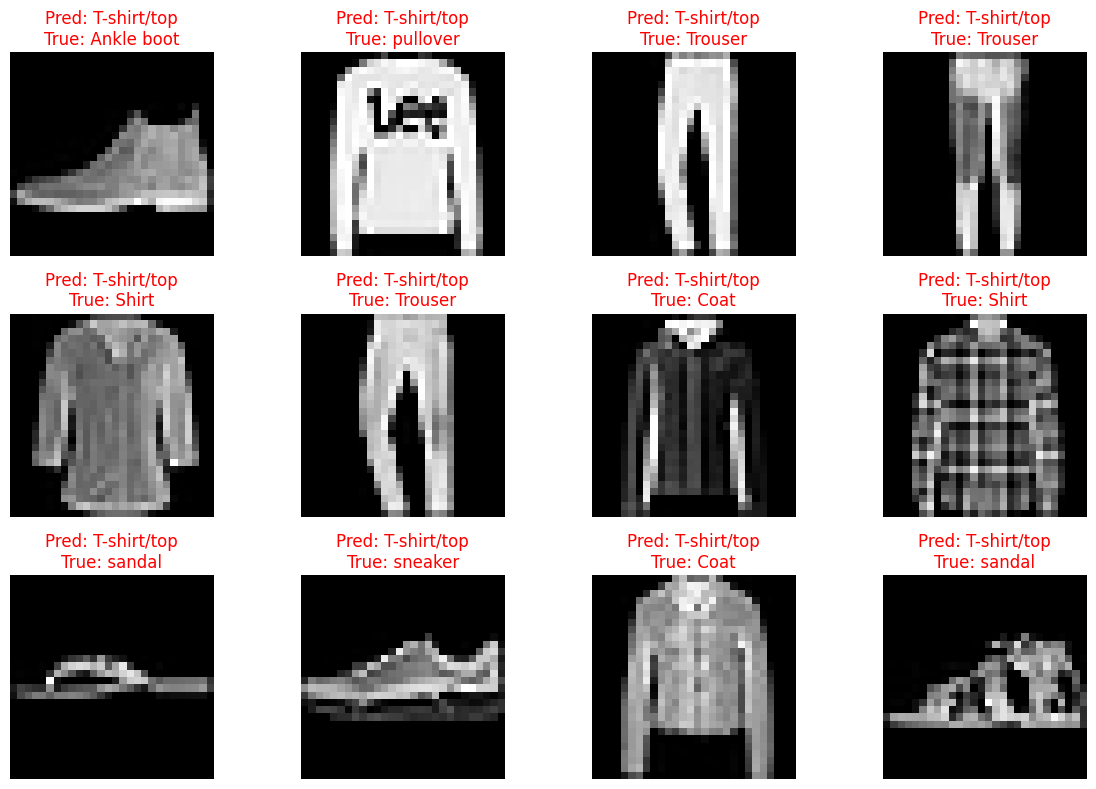

In [12]:
plt.figure(figsize=(12, 8))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(X_test[i], cmap='gray')
    pred_label = class_names[y_pred[i]]
    true_label = class_names[y_test[i]]
    color='green' if y_pred[i] == y_test[i] else 'red'
    plt.title(f'Pred: {pred_label}\nTrue: {true_label}', color=color)
    plt.axis('off')
plt.tight_layout()
plt.show()

## Matriz de confusión

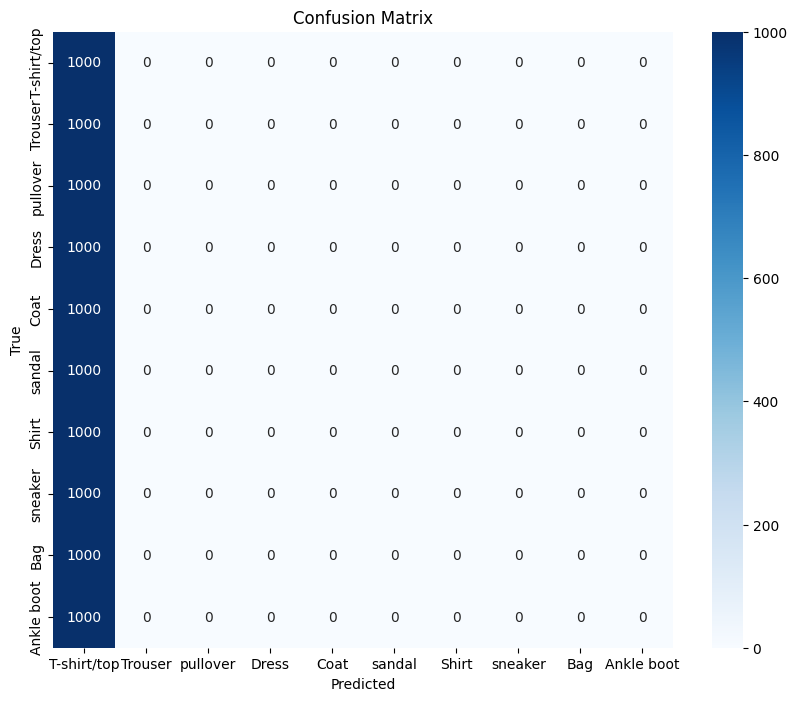

In [13]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

# Creeemos un modelo de CNN para ver como cambia el entrenamniento

In [17]:
model_cnn = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(filters=32, kernel_size=(3,3), activation='relu', name='Conv1'),
    layers.MaxPool2D(pool_size=(2,2), name='Pool1'),
    layers.Conv2D(filters=64, kernel_size=(3,3), activation='relu', name='Conv2'),
    layers.MaxPool2D(pool_size=(2,2), name='Pool2'),
    layers.Flatten(name='capa_de_aplanado'),  # los nombres no pueden tener espacios
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax') # 10 neuronas de salida (softmax para multiclase)
])

# Entrenamos el modelo CNN

In [27]:
# X_train y X_test ya están normalizados (/255) en el preprocesamiento
x_train_cnn = X_train.reshape(-1, 28, 28, 1).astype("float32")
x_test_cnn  = X_test.reshape(-1, 28, 28, 1).astype("float32")
print(x_train_cnn.shape, x_test_cnn.shape)

(60000, 28, 28, 1) (10000, 28, 28, 1)


In [28]:
from tensorflow.keras import optimizers
model_cnn.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [29]:
history_cnn = model_cnn.fit(
    x_train_cnn, y_train,
    epochs = 10,
    validation_split=0.2,
    batch_size = 32
)

Epoch 1/10


ValueError: Exception encountered when calling Sequential.call().

[1m'capa de aplanado' is not a valid root scope name. A root scope name has to match the following pattern: ^[A-Za-z0-9.][A-Za-z0-9_.\\/>-]*$[0m

Arguments received by Sequential.call():
  • inputs=tf.Tensor(shape=(32, 28, 28, 1), dtype=float32)
  • training=True
  • mask=None
  • kwargs=<class 'inspect._empty'>